# Exploration of UNIPLU_BR dataset

In [1]:
import polars as pl
import pandas as pd
import zipfile
import pathlib as Path
import matplotlib.pyplot as plt
import numpy as np
import geopandas

import pipeline_funcs as pf 
import visualize as viz


In [2]:
# Function taken from GitHub for reading zip file: https://github.com/LARHENA/UNIPLU-BR/blob/main/Scripts%20UNIPLU-BR.ipynb
# adapted to work with polars LazyFrames
def read_UNIPLU_BR(zip_path, table='table_data'):
    """Read one table ('table_data' = rainfall readings, 'table_info' = gauge metadata) from a UNIPLU-BR zip
    as a LazyFrame; an empty LazyFrame if the zip or the table is missing."""
    parquet_file = f"{table}.parquet"
    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            with zf.open(parquet_file) as f:
                lf = pl.scan_parquet(f) # LAZY evaluation
        return lf
    except FileNotFoundError:
        print(f"Error: File {zip_path} not found.")
        return pl.LazyFrame()
    except KeyError:
        print(f"Error: {parquet_file} not found inside the ZIP archive.")
        return pl.LazyFrame()

In [3]:
years = [int(y) for y in pf.DEFAULT_YEARS] # pf.DEFAULT_YEARS as integers

In [4]:
rainfall_data = pf.RAINFALL_CLEANED_DIR / "data"
rainfall_info = pf.RAINFALL_CLEANED_DIR / "info" # for metadata

# The UNIPLU-BR zip files, one per state and year (eg SP_2010.zip), have to be downloaded first
if not pf.UNIPLU_DIR.is_dir():
    raise FileNotFoundError(
        f"UNIPLU-BR rain gauge data not found: {pf.UNIPLU_DIR} does not exist. Download the dataset from {pf.UNIPLU_URL}, "
        f"unzip it and store the zip files per state and year (eg SP_2010.zip) in the data folder, in a subfolder "
        f"called '{pf.UNIPLU_DIR.name}'."
    )

# Multiple states and years
states = [state for state in pf.UF_ABBR_TO_CODE if state != "ES"]

# Create two dicts (one LazyFrame per year) to store the different types of tables

rainfall_data_dict = dict()
rainfall_info_dict = dict()

for year in years:
    # Reset the lists once per year, so all states of that year are collected together
    data_list = []
    info_list = []
    for state in states:
        file_path = pf.UNIPLU_DIR / f'{state}_{year}.zip'

        # Loading the rainfall data table
        temp_data_lf = read_UNIPLU_BR(file_path, 'table_data')
        if not temp_data_lf.limit(1).collect().is_empty():
            data_list.append(temp_data_lf)

        # Loading the information table (metadata)
        temp_info_lf = read_UNIPLU_BR(file_path, 'table_info')
        if not temp_info_lf.limit(1).collect().is_empty():
            info_list.append(temp_info_lf)

    # Consolidate all rainfall data (after looping over ALL states)
    lf_total_data = pl.concat(data_list)

    # Consolidate station information and remove duplicates 
    # (as the same station may appear across different years)
    lf_total_info = pl.concat(info_list).unique(subset=['gauge_code'])

    rainfall_data_dict[str(year)] = lf_total_data
    rainfall_info_dict[str(year)] = lf_total_info

In [5]:
# check if cleaned data already exists to avoid saving again unnecessarily
cleaned_exists = all((rainfall_data / f"{year}_data.parquet").is_file() and (rainfall_info / f"{year}_info.parquet").is_file()
                     for year in pf.DEFAULT_YEARS)

## Investigating sensor networks
Available networks:
- CEMADEN: National Center for Monitoring and Early Warning of Natural Disasters.
- INMET: National Institute of Meteorology.
- ANA (Hidroweb): National Water and Sanitation Agency.
- Telemetria: Hydrological monitoring telemetry system.
- ICEA: Institute of Air Space Control.

First let's see how these are represented in the data:


In [6]:

all_network_names = set()
for year in years:
    network_names = pl.Series(rainfall_info_dict[str(year)].select(pl.col("network")).unique().collect()).to_list()
    all_network_names = all_network_names.union(network_names)
    print(f"Networks present in {year}:", sorted(network_names))
print("---------------------")
print("Unique network names across all years:", all_network_names)

Networks present in 2001: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2002: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2003: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2004: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2005: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2006: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2007: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2008: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2009: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2010: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2011: ['Hidroweb diário', 'ICEA', 'INMET diário', 'INMET subdiário']
Networks present in 2

Conclusions:
- We don't need any sub-daily data so ``'INMET subdiário'`` can be excluded
-  ``CEMADEN`` and ``Telemetria`` only appear after 2014 so no need to do anything with those for data before then.
---
Looking at the graphs on the GitHub, using **Hidroweb daily is probably sufficient since it has good coverage**. Let's do this unless it turns out to not be possible. 
Source: https://github.com/LARHENA/UNIPLU-BR/tree/main

This also hopefully saves me having to do the daily aggregation operation which is expensive and as it turns out, unnecessary

In [7]:
if not cleaned_exists:
    # Save the results of filtering and concatenation
    for folder in (rainfall_data, rainfall_info):
        folder.mkdir(parents=True, exist_ok=True)
    data_dict = dict()
    info_dict = dict()
    for year in years:
        data, info = rainfall_data_dict[str(year)], rainfall_info_dict[str(year)]

        relevant_info = info.filter(pl.col('network') == "Hidroweb diário").collect() # use only this network
        relevant_info.write_parquet(Path.Path(rainfall_info / f"{year}_info.parquet")) # save as parquet (faster to read)

        relevant_readings = data.join(relevant_info.lazy().select('gauge_code'), on='gauge_code', how='semi').collect()
        relevant_readings.write_parquet(Path.Path(rainfall_data / f"{year}_data.parquet"))

        data_dict[str(year)] = relevant_readings.lazy()
        info_dict[str(year)] = relevant_info.lazy()
        print("Saved for year", year)
else:
    data_dict = dict()
    info_dict = dict()
    for year in years:
        data_dict[str(year)] = pl.scan_parquet(Path.Path(rainfall_data / f"{year}_data.parquet"))
        info_dict[str(year)] = pl.scan_parquet(Path.Path(rainfall_info / f"{year}_info.parquet"))

My first thought was that the simplest way to combine the dengue + rainfall data at the municipality level would be by string matching the names. The rain data contains 'city' which... doesn't mean much, since 'CIDADE' isn't an option anywhere, it might just be a translation quirk. Below, I try to check if it corresponds. Unfortunately, the answer is no.

In [8]:
all_city_names = set()
for year in years:
    city_names = pl.Series(info_dict[str(year)].select(pl.col("city")).unique().collect()).to_list()
    all_city_names = all_city_names.union(set(city_names))
print("---------------------")
print("Unique city names across all years:", all_city_names)
print(len(all_city_names))

---------------------
Unique city names across all years: {'Três Passos', 'Santo Antônio do Monte', 'Boracéia', 'Tarauacá', 'Pilar', 'Capinzal', 'Campos Gerais', 'Barreirinha', 'Braganey', 'Borda da Mata', 'Pirassununga', 'Boa Vista do Incra', 'Barro Alto', 'Boa Esperança', 'Aparecida', 'Iepê', 'São Vendelino', 'Capivari', 'Bofete', 'Beneditinos', 'Flores do Piauí', 'Torixoréu', 'Canutama', 'Bandeirantes', 'Paracatu', 'Vargem Grande', 'Mariana', 'Calçoene', 'Bossoroca', 'Marechal Cândido Rondon', 'Lagoa da Prata', 'Jacareí', 'Coração de Jesus', 'Goiatins', 'São Miguel dos Campos', 'Porto Estrela', 'Ibitiara', 'Baianópolis', 'Abreulândia', 'Mimoso de Goiás', 'Ipú', 'Bataguassu', 'Teixeira', 'Aracoiaba', 'Rio Verde', 'Pentecoste', 'Missal', 'Córrego Novo', 'Peruibe', 'Várzea Branca', 'Araguacema', 'Solânea', 'Pium', 'Pereira Barreto', 'Ribeirão Preto', 'Frecheirinha', 'Nova Iguaçu', 'Aragoiânia', 'Cacimba de Areia', 'Porto Murtinho', 'Alvorada', 'Nova Friburgo', 'Alagoa Nova', 'Glorinha'

In [9]:
municipality_codes = pf.load_municipality_codes()
names = pl.Series(municipality_codes.select('MUNICÍPIO - IBGE')).to_list()

In [10]:
common = all_city_names.intersection(set(names))
print(f"The IBGE municipality table has {len(names)} names and the rain gauge metadata {len(all_city_names)}; they have {len(common)} in common")

The IBGE municipality table has 5571 names and the rain gauge metadata 2897; they have 2744 in common


## Figuring out spatial resolution

### Attempt 1: Municipality
Clearly, I can't use city names as a proxy for municipality, so I either have to use latitude/longitude or state-level data, which might be too coarse, since Brazil is huge and states can span many different biomes, which will of course affect rainfall patterns. I'm going to try and use the lat/long strategy first, since it's easier to move from fine to coarse than the other way around.

In [11]:
import geobr # contains the brazil geometry data in geopandas format
municip_geom = geobr.read_municipality(year=2010) # pick a year in the middle to get the polygons


municipalities_2010_simplified.parquet:   0%|          | 0.00/18.4M [00:00<?, ?B/s]
municipalities_2010_simplified.parquet:  19%|█▉        | 3.46M/18.4M [00:00<00:00, 34.5MB/s]
municipalities_2010_simplified.parquet:  46%|████▌     | 8.42M/18.4M [00:00<00:00, 43.3MB/s]
municipalities_2010_simplified.parquet:  71%|███████   | 13.0M/18.4M [00:00<00:00, 44.4MB/s]
municipalities_2010_simplified.parquet:  95%|█████████▍| 17.5M/18.4M [00:00<00:00, 30.2MB/s]
municipalities_2010_simplified.parquet: 100%|██████████| 18.4M/18.4M [00:00<00:00, 34.0MB/s]


In [12]:
municip_geom

,code_muni,name_muni,code_state,abbrev_state,name_state,code_region,name_region,year,geometry
0,1100015.0,Alta Floresta d'Oeste,11.0,RO,Rondônia,1.0,Norte,2010.0,"POLYGON ((-62.24906 -11.90039, -62.25782 -11.9..."
1,1100023.0,Ariquemes,11.0,RO,Rondônia,1.0,Norte,2010.0,"POLYGON ((-63.09013 -9.78237, -63.23252 -9.787..."
2,1100031.0,Cabixi,11.0,RO,Rondônia,1.0,Norte,2010.0,"POLYGON ((-60.37161 -13.31859, -60.70518 -13.3..."
3,1100049.0,Cacoal,11.0,RO,Rondônia,1.0,Norte,2010.0,"POLYGON ((-61.42678 -11.11398, -61.5008 -11.11..."
4,1100056.0,Cerejeiras,11.0,RO,Rondônia,1.0,Norte,2010.0,"POLYGON ((-61.41265 -13.23375, -61.4075 -13.23..."
...,...,...,...,...,...,...,...,...,...
5560,5222005.0,Vianópolis,52.0,GO,Goiás,5.0,Centro-Oeste,2010.0,"POLYGON ((-48.54222 -16.74198, -48.54473 -16.7..."
5561,5222054.0,Vicentinópolis,52.0,GO,Goiás,5.0,Centro-Oeste,2010.0,"POLYGON ((-49.90588 -17.61533, -49.91332 -17.6..."
5562,5222203.0,Vila Boa,52.0,GO,Goiás,5.0,Centro-Oeste,2010.0,"POLYGON ((-46.98434 -14.91057, -47.0547 -14.90..."
5563,5222302.0,Vila Propício,52.0,GO,Goiás,5.0,Centro-Oeste,2010.0,"POLYGON ((-48.86191 -15.0918, -48.87066 -15.10..."


In [13]:
municip_geom.crs.to_epsg() # type of coordinates - code

4674

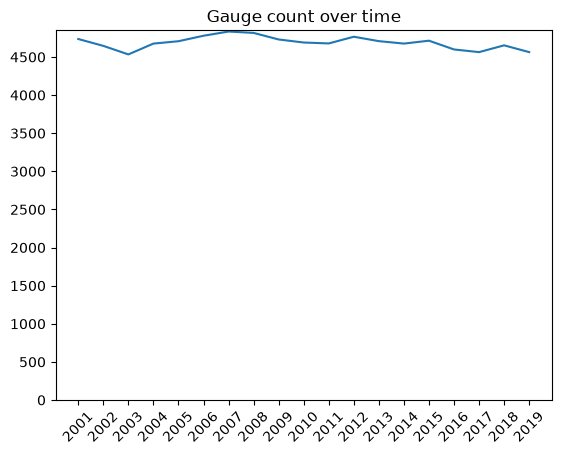

In [14]:
# We need all the locations of the sensors, and these should be unique

# Secondary check to make sure no gauge has more than one lat/long coordinate
# Checked this for all years, and all dataframes were empty, meaning yes, all the gauges seem to have unique coordinates
# display(info_lf.group_by('gauge_code')
#    .agg(pl.col('lat').n_unique().alias('n_lat'),
#        pl.col('long').n_unique().alias('n_lon'))
#    .filter((pl.col('n_lat') > 1) | (pl.col('n_lon') > 1))
#    .collect())

# Check whether gauges have any duplicates in any years
num_gauges_over_time = []
for year, info_lf in info_dict.items():
    num_gauges_unique = info_lf.select('gauge_code').unique().count().collect().item()
    num_gauges = info_lf.select('gauge_code').count().collect().item()
    

    if np.abs(num_gauges - num_gauges_unique) > 0:
        print(f"Mismatch; at least one gauge is repeated in year {year}")
        num_gauges_over_time.append(-1)
    else:
        num_gauges_over_time.append(num_gauges)


plt.plot([int(year) for year in info_dict.keys()], num_gauges_over_time)
plt.xticks([int(year) for year in info_dict.keys()], rotation=45)
plt.yticks(np.arange(0, max(num_gauges_over_time), 500))
plt.title('Gauge count over time')
plt.show()

There are fortunately no duplicates :) so we don't need to filter for them. We see that the count fluctuates a little over time, but this might just be because some don't have readings, rather than the actual number of sensors changing. There's no real way to tell. I chose the axis like this because I wanted to see, relatively, how much change occurs, and the plot shows that it remains roughly stable just over 4500, so the actual number of sensors is probably around there.

In order to capture the location of as many of these as possible, I will still go over all the years, then get the unique values.

In [15]:
unique_locations_lf = pl.concat(
    [lf.select('gauge_code', 'lat', 'long') for lf in info_dict.values()],
    how='vertical_relaxed' # coerce columns into common supertype (eg int) if mismatched 
)

In [16]:
# Need to convert to pandas since geopandas is built on... well, pandas
# Then use this to build a geo dataframe containing all the points of the sensors
locations_df = unique_locations_lf.collect().to_pandas()
gauges_gdf = geopandas.GeoDataFrame(
    locations_df,
    geometry=geopandas.points_from_xy(locations_df['long'], locations_df['lat']),  # x=long first, y=lat
    crs="EPSG:4326", # standard gps coordinate system assumed since no metadata on this is given
)
gauges_gdf.geometry.head()

0    POINT (-57.8917 -21.7014)
1       POINT (-42.2167 -15.8)
2       POINT (-38.95 -4.5833)
3     POINT (-38.0333 -8.2833)
4      POINT (-45.1833 -10.65)
Name: geometry, dtype: geometry


states_2010_simplified.parquet:   0%|          | 0.00/1.59M [00:00<?, ?B/s]
states_2010_simplified.parquet: 100%|██████████| 1.59M/1.59M [00:00<00:00, 18.9MB/s]


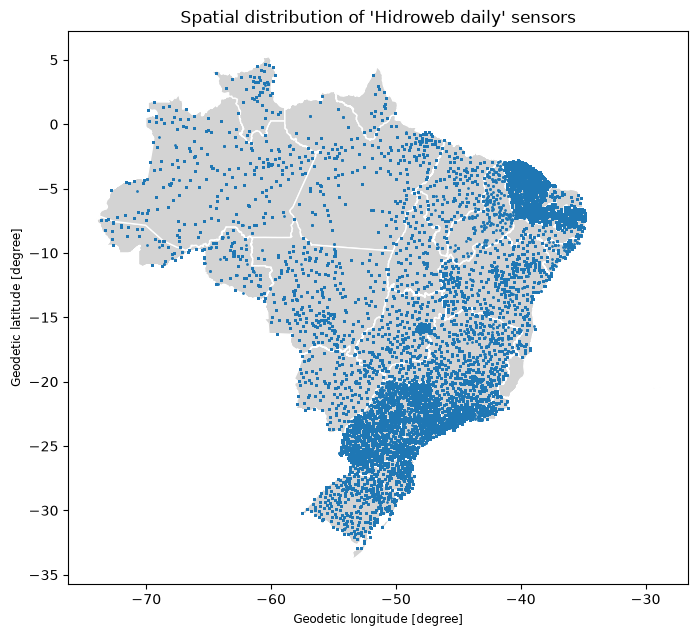

In [17]:
# visual check that the sensors land at least roughly in the right place
# used states because municipalities would be messy to plot
brazil = geobr.read_state(year=2010) # 2010 also used, for consistency

ax = brazil.plot(color='lightgrey', edgecolor='white', figsize=(8, 8))
gauges_gdf.to_crs(brazil.crs).plot(ax=ax, markersize=1)
plt.title("Spatial distribution of 'Hidroweb daily' sensors")
plt.show()

In [18]:
# Check how many points landed outside brazil geometry 
pts = gauges_gdf.to_crs(brazil.crs)
outside = pts[~pts.within(brazil.union_all())]
print(f"{len(outside)} points land outside the country's outlines")

40 points land outside the country's outlines


From the visual inspection plus the calculation above, we can assume that the points calculated make sense. A few land outside of the strict boundaries but I think they're probably not off by much since the plot shows no obviously wrong points, just some that are very slightly past the boundary, in some places. It is clear that not all municipalities will have sensors though, especially in the North-West of the country.

In [19]:
joined = geopandas.sjoin(pts, municip_geom[['code_muni', 'geometry']], predicate='within')
covered = joined['code_muni'].nunique()
print(f"{(covered/len(municip_geom))*100:.2f}% municipalities have at least one gauge")

54.90% municipalities have at least one gauge


### Attempt 2: Health regions
The coverage at municipality-level is too low to realistically work with. Other options include health region, so let's try that. It's finer-grain than state-level, but coarser than municipality. It also conveniently appears in both the dengue dataset and the data that geobr makes available. 

Unfortunately, region ID ``ID_REGIONA``, though present in all years in the dengue dataset, has quite high missingness for some years (eg, 33% in one case), which I will have to deal with if I decide to work with regions

In [20]:
health_regions = geobr.read_health_region(year=2013) # 2013 was closest year to 2010 available
health_regions


healthregions_2013_simplified.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]
healthregions_2013_simplified.parquet:   1%|          | 172k/18.6M [00:00<00:11, 1.54MB/s]
healthregions_2013_simplified.parquet:  17%|█▋        | 3.20M/18.6M [00:00<00:00, 17.7MB/s]
healthregions_2013_simplified.parquet:  32%|███▏      | 6.03M/18.6M [00:00<00:00, 21.9MB/s]
healthregions_2013_simplified.parquet:  53%|█████▎    | 9.90M/18.6M [00:00<00:00, 28.1MB/s]
healthregions_2013_simplified.parquet:  69%|██████▊   | 12.7M/18.6M [00:01<00:00, 6.05MB/s]
healthregions_2013_simplified.parquet:  79%|███████▉  | 14.7M/18.6M [00:02<00:00, 4.98MB/s]
healthregions_2013_simplified.parquet:  86%|████████▋ | 16.0M/18.6M [00:02<00:00, 4.94MB/s]
healthregions_2013_simplified.parquet:  92%|█████████▏| 17.1M/18.6M [00:02<00:00, 4.85MB/s]
healthregions_2013_simplified.parquet:  97%|█████████▋| 18.0M/18.6M [00:02<00:00, 4.99MB/s]
healthregions_2013_simplified.parquet: 100%|██████████| 18.6M/18.6M [00:02<00:00, 6.45MB/

,code_muni,name_muni,code_health_region,name_health_region,code_health_macroregion,name_health_macroregion,code_state,abbrev_state,name_state,code_region,name_region,code_muni6,year,geometry
0,1100015.0,Alta Floresta d'Oeste,11005.0,Zona da Mata,1101.0,Macrorregional Ii (Cacoal,11.0,RO,Rondônia,1.0,Norte,110001.0,2013.0,"POLYGON ((-62.19929 -11.82788, -62.18945 -11.8..."
1,1100023.0,Ariquemes,11001.0,Vale do Jamari,1102.0,Macrorregiao I - Porto Ve,11.0,RO,Rondônia,1.0,Norte,110002.0,2013.0,"POLYGON ((-62.53648 -9.73222, -62.52765 -9.736..."
2,1100031.0,Cabixi,11006.0,Cone Sul,1101.0,Macrorregional Ii (Cacoal,11.0,RO,Rondônia,1.0,Norte,110003.0,2013.0,"POLYGON ((-60.37103 -13.36186, -60.37134 -13.3..."
3,1100049.0,Cacoal,11002.0,Café,1101.0,Macrorregional Ii (Cacoal,11.0,RO,Rondônia,1.0,Norte,110004.0,2013.0,"POLYGON ((-61.00059 -10.99224, -61.00103 -11.3..."
4,1100056.0,Cerejeiras,11006.0,Cone Sul,1101.0,Macrorregional Ii (Cacoal,11.0,RO,Rondônia,1.0,Norte,110005.0,2013.0,"POLYGON ((-61.50149 -13.00501, -61.49426 -13.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5564,5222005.0,Vianópolis,52002.0,Centro Sul,5210.0,Macrorregiao Centro Sudes,52.0,GO,Goiás,5.0,Centro-Oeste,522200.0,2013.0,"POLYGON ((-48.38114 -16.63141, -48.38044 -16.6..."
5565,5222054.0,Vicentinópolis,52002.0,Centro Sul,5210.0,Macrorregiao Centro Sudes,52.0,GO,Goiás,5.0,Centro-Oeste,522205.0,2013.0,"POLYGON ((-49.84456 -17.58262, -49.8402 -17.58..."
5566,5222203.0,Vila Boa,52003.0,Entorno Norte,5207.0,Macrorregiao Nordeste,52.0,GO,Goiás,5.0,Centro-Oeste,522220.0,2013.0,"POLYGON ((-47.11416 -14.67412, -47.11313 -14.6..."
5567,5222302.0,Vila Propício,52018.0,São Patrício Ii,5209.0,Macrorregiao Centro-Norte,52.0,GO,Goiás,5.0,Centro-Oeste,522230.0,2013.0,"POLYGON ((-48.75744 -14.86168, -48.74989 -14.8..."


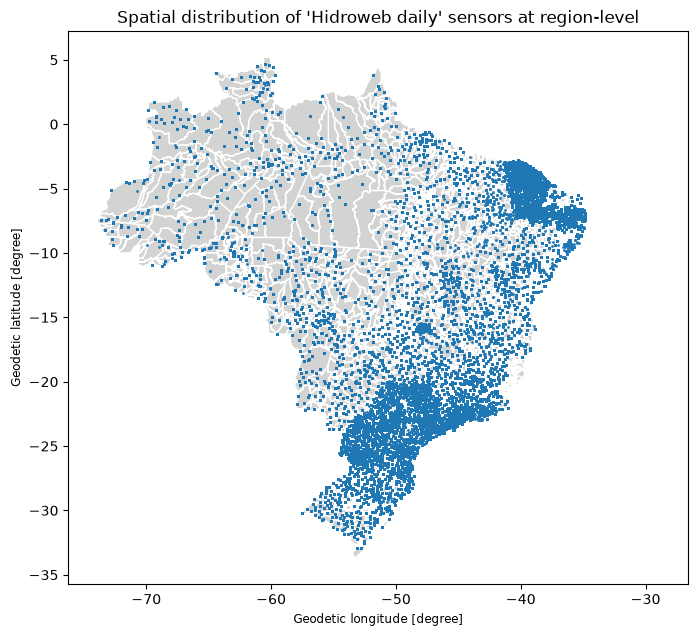

In [21]:
ax = health_regions.plot(color='lightgrey', edgecolor='white', figsize=(8, 8))
gauges_gdf.to_crs(health_regions.crs).plot(ax=ax, markersize=1)
plt.title("Spatial distribution of 'Hidroweb daily' sensors at region-level")
plt.show()

In [22]:
# check spatial coverage
pts_hr = pts.to_crs(health_regions.crs)
num_regions = health_regions['code_health_region'].nunique()
joined = geopandas.sjoin(
    pts_hr, health_regions[['code_health_region', 'geometry']], predicate='within'
)
covered = joined['code_health_region'].nunique()
print(f"{covered/num_regions*100:.1f}% of regions have at least 1 gauge")

98.6% of regions have at least 1 gauge


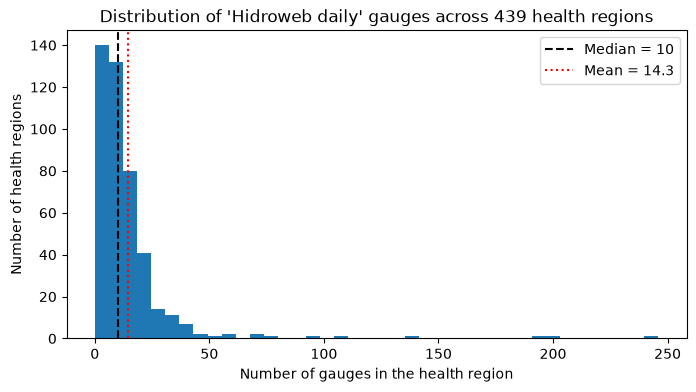

Regions with no gauge: 6, with fewer than 5: 90
Best-covered 10% of regions hold 38% of all gauges (max 246 gauges in one region)


In [23]:
def plot_gauges_per_region(joined, health_regions, bins=40):
    """Histogram of the number of distinct gauges per health region (regions without gauges count as 0), to show how
    unevenly they are spread. joined has one row per gauge location per year, hence nunique. Returns the count per region."""
    gauges_per_region = (
        joined.groupby("code_health_region")["gauge_code"].nunique()
        .reindex(health_regions["code_health_region"].unique(), fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(gauges_per_region, bins=bins)
    # median: the typical region; mean: pulled up by the few regions with very many gauges, so the gap shows the skew
    ax.axvline(gauges_per_region.median(), color="black", linestyle="--", label=f"Median = {gauges_per_region.median():.0f}")
    ax.axvline(gauges_per_region.mean(), color="red", linestyle=":", label=f"Mean = {gauges_per_region.mean():.1f}")
    ax.set(xlabel="Number of gauges in the health region", ylabel="Number of health regions",
           title=f"Distribution of 'Hidroweb daily' gauges across {len(gauges_per_region)} health regions")
    ax.legend()
    plt.show()

    # a few numbers that summarise how uneven the spread is
    top_10pct = gauges_per_region.sort_values(ascending=False).head(len(gauges_per_region) // 10)
    print(f"Regions with no gauge: {(gauges_per_region == 0).sum()}, with fewer than 5: {(gauges_per_region < 5).sum()}")
    print(f"Best-covered 10% of regions hold {top_10pct.sum() / gauges_per_region.sum() * 100:.0f}% of all gauges "
          f"(max {gauges_per_region.max()} gauges in one region)")
    return gauges_per_region

gauges_per_region = plot_gauges_per_region(joined, health_regions)

This looks promising, but as the spatial distribution demonstrates, the average rainfall readings for a given region are going to have drastically different reliability due to the massive imbalance in the number of sensors.

Depending on how much variability there is, it may simply not be viable to do a nationwide predictive model and it may be better to focus on regions in a well-covered state or something like that. Rio de Janeiro and São Paulo would be good candidates for this as they also have high population densities, and so the model is more likely to have real-world utility.

I considered the possibility of adding data from other networks, but looking at the graphs provided on the authors' Github, it's not likely to help much since the spatial distribution for all the networks suffers from similar issues; the East coast is well covered while most of the interior, especially the North West, is not. So it would add work and computational cost without significant benefit.

(In general, not just for the network shown above) The lack of sensors in the North West is probably because this is where most of the Amazon rainforest is concentrated (see [image](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Frioandlearn.com%2Fwp-content%2Fuploads%2F2025%2F08%2Fmap-rainforest-edited.png&f=1&nofb=1&ipt=9be55cb7744a394b1ddc08e914b554cd68825e39e08331879ae86c2c6c142b79&ipo=images)). It is notoriously dense and not fully explored, so it makes sense that there would be fewer sensors here. Similarly, it makes sense that the coast would have the best coverage since it also has the highest population density (see [this population density map estimate from 2020](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.worldmappdf.com%2Fimg%2Fpopulation_density_map_brazil.jpg&f=1&nofb=1&ipt=fa2bdd14fb90ca6402a4ba9cdeb0a2fad5b63f17b780c05d26f2e5a19f53e392&ipo=images)) and the government likely prioritizes investigation in areas where things like floods are most likely to affect the greatest percentage of people.


In [24]:
# save the rain data + location, for each year, for downstream analysis
# state code comes from the health region table (each health region belongs to exactly one state)
region_to_state = pl.from_pandas(
    health_regions[["code_health_region", "code_state"]].drop_duplicates()
).cast(pl.Int64)

gauges = (
    pl.from_pandas(joined[["gauge_code", "lat", "long", "code_health_region"]])
    .with_columns(
        pl.col("gauge_code").cast(pl.String),
        pl.col("code_health_region").cast(pl.Int64),
    )
    .unique(subset="gauge_code")
    .join(region_to_state, on="code_health_region", how="left")
    .lazy()
)

rainfall_data_st = pf.RAINFALL_CLEANED_DIR / "full_spatiotemporal"
if all((rainfall_data_st / f"{year}_rain_with_region.parquet").is_file() for year in data_dict):
    print(f"Rain data with regions already saved in {rainfall_data_st}")
else:
    rainfall_data_st.mkdir(parents=True, exist_ok=True)
    for year, readings_lf in data_dict.items():
        (
            readings_lf
            .join(gauges, on="gauge_code", how="left")
            .sink_parquet(rainfall_data_st / f"{year}_rain_with_region.parquet")
        )

Rain data with regions already saved in ..\output\Rainfall_cleaned\full_spatiotemporal


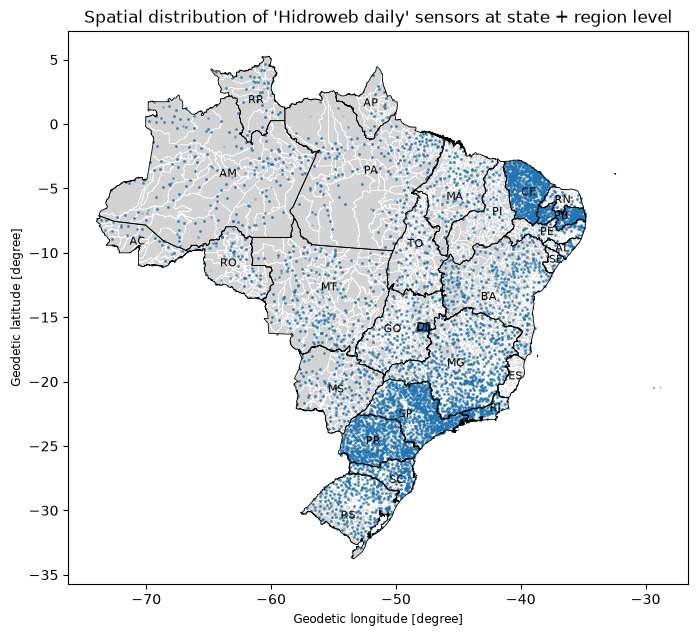

In [25]:
# similar plot to earlier but with state outlines
ax = health_regions.plot(color='lightgrey', linewidth=0.5, edgecolor='white', figsize=(8, 8))
gauges_gdf.to_crs(health_regions.crs).plot(ax=ax, markersize=1, alpha=0.05)
brazil.boundary.plot(ax=ax, color='black', linewidth=0.6)   # outlines only

# add state labels
for _, row in brazil.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(row['abbrev_state'], xy=(pt.x, pt.y),
                ha='center', va='center', fontsize=8)

plt.title("Spatial distribution of 'Hidroweb daily' sensors at state + region level")
plt.show()

Given that the sensor distribution is pretty sparse in other states, it probably makes most sense to focus on the ones that have decent coverage; CE, PB, SP, PR and I will try to look at RJ as well since it still has reasonable coverage and [RJ and SP are in the top-3 states with the highest population](https://www.geocountries.com/states/brazil?sort=population) so a predictive model could potentially benefit the most amount of people. In terms of population density, [RJ and SP top the list](https://www.geocountries.com/states/brazil?sort=density).

Making a model for other states would probably lead to them having low predictive power (at least based on the rainfall estimates), and a national model would probably perform even worse since most of the country is sparsely covered. So I've decided it's best to focus on these that probably have a decent chance.

- CE = Ceará
- PB = Paraíba
- SP = São Paulo
- PR = Paraná
- RJ = Rio de Janeiro

# Seasonality
I wanted to look at how rainfall patterns change yearly in order to see seasonal patterns and how these change with state.
Highest ever recorded rainfall value comes from [here](https://gadri.net/events/Kobiyama%20%28GADRI-report%202023%29-Sao%20Sebastiao-2023-Fev.pdf)

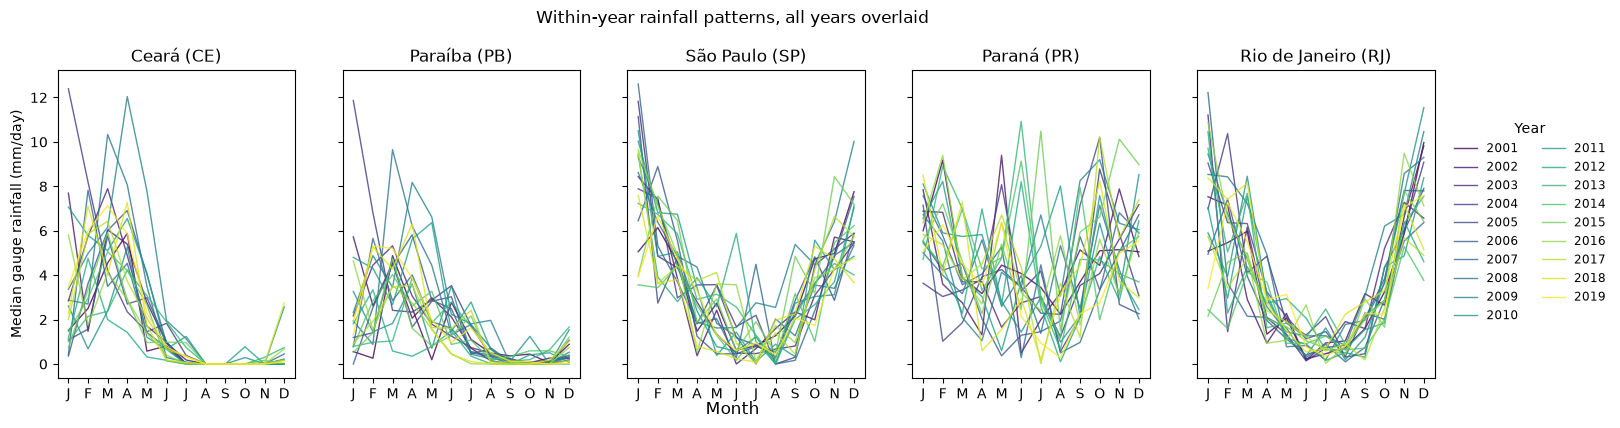

In [26]:
# Monthly rainfall per focus state, one line per year.
# Per gauge: mean daily rainfall for each month (mm/day; robust to gauges with missing days).
# Per state: median across gauges to be more robust to outliers since my outlier detection / handling is basically nonexistent.
# The per-gauge values (gauge_monthly) and the number of gauges are kept too, to show how much the gauges disagree (below)
gauge_monthly = pl.concat(
    [
        data_dict[str(year)]
        .join(info_dict[str(year)].select("gauge_code", "state"), on="gauge_code", how="inner")
        .filter(pl.col("rain_mm") < 700) # really basic 'outlier' filter; highest recorded rainfall in Brazil was 682mm in 24 hours
        .filter(pl.col("state").is_in(pf.FOCUS_STATES))
        .group_by("state", "gauge_code", pl.col("datetime").dt.month().alias("month"))
        .agg(pl.col("rain_mm").mean().alias("gauge_daily_rain_mm"))
        .with_columns(pl.lit(int(year)).alias("year"))
        for year in years
    ],
    how="vertical",
).collect()

monthly_rain = (
    gauge_monthly
    .group_by("state", "year", "month")
    .agg(pl.col("gauge_daily_rain_mm").median().alias("median_daily_rain_mm"), pl.len().alias("n_gauges"))
    .sort("state", "year", "month")
)

fig, axes = plt.subplots(1, len(pf.FOCUS_STATES), figsize=(18, 4), sharey=True)
cmap = plt.get_cmap("viridis")
norm = plt.Normalize(min(years), max(years)) # colours still run from early (purple) to late (yellow) years
months = np.arange(1, 13)
month_letters = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

for ax, abbr in zip(axes, pf.FOCUS_STATES):
    state_df = monthly_rain.filter(pl.col("state") == abbr)
    for year in years:
        group = state_df.filter(pl.col("year") == year)
        ax.plot(group["month"], group["median_daily_rain_mm"], color=cmap(norm(year)), linewidth=1, alpha=0.8,
                label=str(year))
    ax.set_title(f"{viz.uf_label(abbr)} ({abbr})")
    ax.set_xticks(months, month_letters)

axes[0].set_ylabel("Median gauge rainfall (mm/day)")
fig.supxlabel("Month")
fig.suptitle("Within-year rainfall patterns, all years overlaid", y=1.03)

# Years are discrete, so a legend instead of a colour bar. Every panel has the same years in the same colours,
# so the legend is built from the first panel only (otherwise each year would be listed once per panel).
# subplots_adjust leaves space on the right for the legend; two columns so that 19 years fit within the height of the panels
fig.subplots_adjust(right=0.89)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Year", loc="center left", bbox_to_anchor=(0.895, 0.5), ncol=2,
           fontsize="small", frameon=False)
plt.show()

It is incredibly strange that the state PR seems to have no obvious rainfall patterns. Four states are probably already enough to observe state-dependent patterns, and I suppose it's also quite neat to have two of each displaying somewhat similar patterns (CE + PB, SP + RJ). So, under time constraints and not wishing to give myself further headaches, I will drop Paraná from the analysis.

### Variability in state readings
The lines above are the median across a state's gauges, which hides their distribution. Below, for each state and calendar month, the boxplots show the distribution of the individual gauges' values (the mean daily rainfall of one gauge in one month), with all years pooled, and the bottom row shows how many gauges there are each year.

328 of 475683 gauge-months are above 30 mm/day and not shown


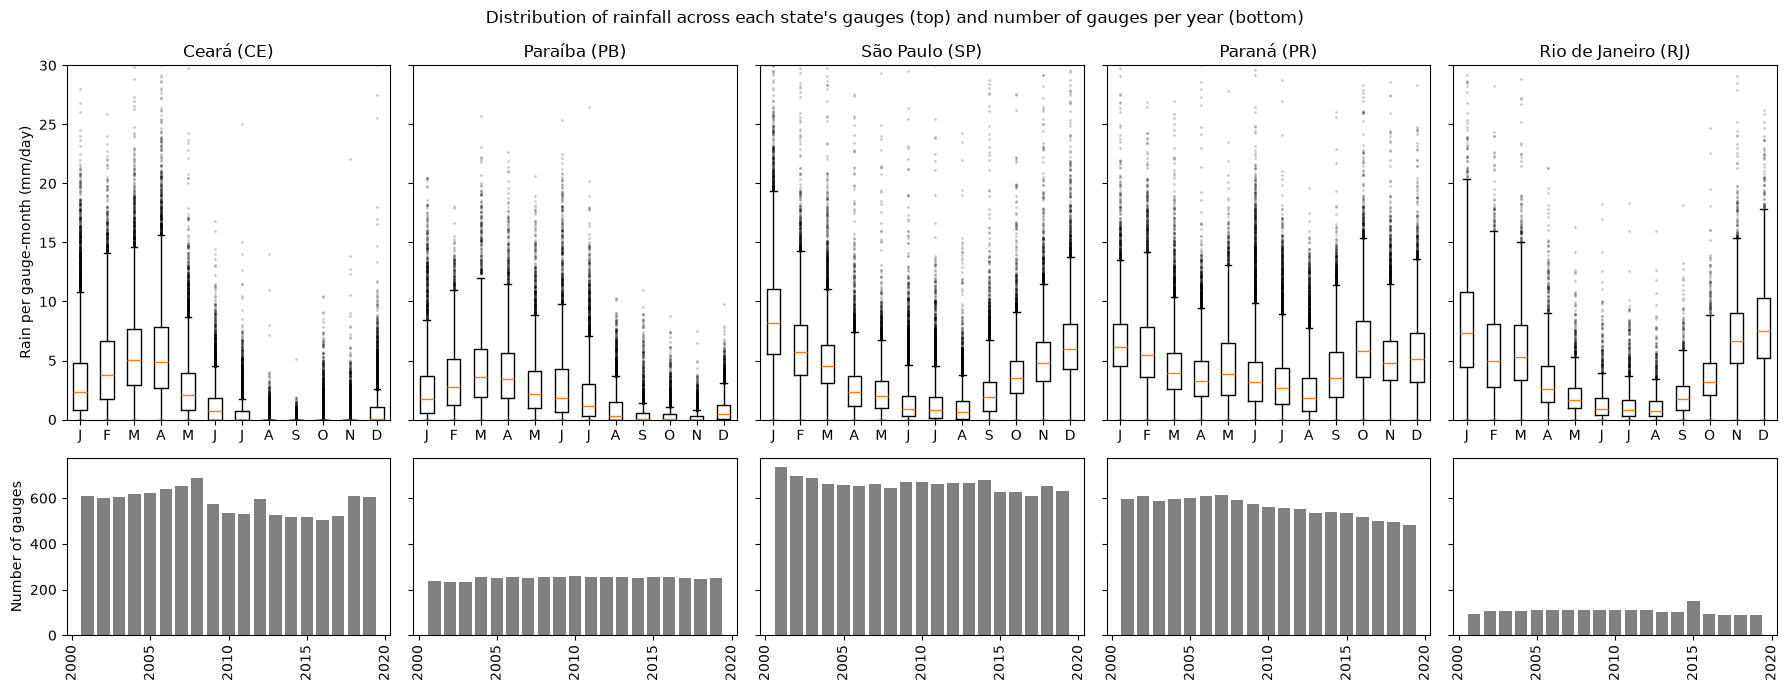

In [27]:
# Distribution of the gauges' monthly values per state and calendar month, all years pooled. Box: middle 50% of the
# gauge-months, orange line: median, whiskers: up to 1.5 x the box height, dots: values beyond that
# Bottom row: gauges per state and year (the most gauges with readings in any month of the year)
# The y-axis stops at 30 mm/day: a month-long average above that is implausible (probably broken gauges), and the few
# such values would squash the boxes
max_shown = 30
print(f"{(gauge_monthly['gauge_daily_rain_mm'] > max_shown).sum()} of {gauge_monthly.height} gauge-months are above {max_shown} mm/day and not shown")
gauges_per_year = monthly_rain.group_by("state", "year").agg(pl.col("n_gauges").max()).sort("state", "year")

fig, axes = plt.subplots(2, len(pf.FOCUS_STATES), figsize=(18, 7), sharey="row", height_ratios=[2, 1])
for (ax_rain, ax_n), abbr in zip(axes.T, pf.FOCUS_STATES):
    s = gauge_monthly.filter(pl.col("state") == abbr)
    ax_rain.boxplot([s.filter(pl.col("month") == m)["gauge_daily_rain_mm"].to_numpy() for m in months],
                    tick_labels=month_letters, flierprops=dict(markersize=1, alpha=0.2))
    ax_rain.set_ylim(0, max_shown)
    ax_rain.set_title(f"{viz.uf_label(abbr)} ({abbr})")
    g = gauges_per_year.filter(pl.col("state") == abbr)
    ax_n.bar(g["year"], g["n_gauges"], color="grey")
    ax_n.tick_params(axis="x", labelrotation=90)
axes[0, 0].set_ylabel("Rain per gauge-month (mm/day)")
axes[1, 0].set_ylabel("Number of gauges")
fig.suptitle("Distribution of rainfall across each state's gauges (top) and number of gauges per year (bottom)")
plt.tight_layout()
plt.show()

The gauges within a state disagree a lot. The long upper whiskers and many dots show that a minority of gauge-months are much wetter than the rest. But because all years are pooled, this spread contains both differences between gauges and differences between years, so it somewhat overstates how much the gauges disagree within a single month. In the dry season of CE and PB most gauge-months are 0 so there the median is 0 and the spread comes from the few gauges that did get rain.

The number of gauges is also very uneven: RJ has only about 100 gauges with readings, against about 250 in PB and 540-650 in CE, PR and SP, and these numbers stay fairly stable over the years (CE dips somewhat between about 2010 and 2016, and PR slowly declines). So the state-level median is a rough summary: in RJ it rests on comparatively few gauges, and in CE and PB on very patchy rainfall. PR does show a seasonal cycle (wetter from October to February, driest in July-August), but a much weaker one than the other states. This clearly shows that the reliability of the readings is not the same across states.